# 1. Setup & konfigurasi
Semua path dan konstanta dikumpulkan di satu tempat supaya mudah diubah. Kolom dikelompokkan berdasarkan peran statistiknya, bukan tipe datanya — ini penting karena kolom ID wilayah bertipe int tetapi sebenarnya nominal (kode 22 > 12 tidak bermakna).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import f1_score

SEED = 42
DATA_DIR = Path("../data")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "damage_grade"
ID_COL = "building_id"
GRADE_ORDER = [f"Grade {i}" for i in range(1, 6)]
# Palet sekuens satu-hue: makin gelap = makin parah
GRADE_COLORS = ["#fee391", "#fec44f", "#fe9929", "#d95f0e", "#993404"]
GRADE_PALETTE = dict(zip(GRADE_ORDER, GRADE_COLORS))

GEO_COLS = ["district_id", "vdcmun_id", "ward_id"]          # nominal
NUM_COLS = ["count_floors_pre_eq", "age_building",
            "plinth_area_sq_ft", "height_ft_pre_eq"]        # numerik kontinu/diskrit

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelsize": 10})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

In [ ]:
def save_fig(name: str) -> None:
    """Simpan figure aktif ke ``reports/figures/<name>.png`` (150 dpi).
    Args:
        name: Nama file tanpa ekstensi.
    """
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# 2. Memuat data & pemeriksaan struktur
Pemeriksaan wajib sebelum analisis apa pun: ukuran, tipe, missing value, duplikat, dan konsistensi skema train vs test vs sample_submission (kolom test harus = kolom train tanpa target).

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

print(f"train : train.csv         -> {train.shape[0]:>9,} baris x {train.shape[1]} kolom")
print(f"test  : test.csv          -> {test.shape[0]:>9,} baris x {test.shape[1]} kolom")
print(f"submit: sample_submission.csv -> {sub.shape[0]:>9,} baris  (ukuran test penuh yang diharapkan)")

CAT_COLS = [c for c in train.columns if c not in GEO_COLS + NUM_COLS + [ID_COL, TARGET]]
print(f"\nKolom kategorik ({len(CAT_COLS)}): {CAT_COLS}")

train : train.csv         ->   533,465 baris x 17 kolom
test  : test.csv          ->   228,629 baris x 16 kolom
submit: sample_submission.csv ->   228,629 baris  (ukuran test penuh yang diharapkan)

Kolom kategorik (8): ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure']


In [4]:
# --- Konsistensi skema
print("Kolom train - kolom test :", sorted(set(train.columns) - set(test.columns)))
print("Kolom test - kolom train :", sorted(set(test.columns) - set(train.columns)))
print("Kolom sample_submission  :", list(sub.columns))
print("Contoh label submission  :", sorted(sub[TARGET].unique()))

# --- Kualitas data
quality = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "n_missing": train.isna().sum(),
    "n_unique": train.nunique(),
})
display(quality)
print(f"Duplikat building_id (train)          : {train[ID_COL].duplicated().sum()}")
feat_cols = [c for c in train.columns if c not in (ID_COL, TARGET)]
print(f"Baris duplikat pada fitur (tanpa ID)  : {train.duplicated(subset=feat_cols).sum()}")
print(f"building_id test yang ada di submission: {test[ID_COL].isin(sub[ID_COL]).mean():.1%}")
print(f"building_id test yang bocor di train   : {test[ID_COL].isin(train[ID_COL]).sum()}")

Kolom train - kolom test : ['damage_grade']
Kolom test - kolom train : []
Kolom sample_submission  : ['building_id', 'damage_grade']
Contoh label submission  : ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']


,dtype,n_missing,n_unique
building_id,int64,0,533465
district_id,int64,0,11
vdcmun_id,int64,0,110
ward_id,int64,0,945
count_floors_pre_eq,int64,0,9
age_building,int64,0,170
plinth_area_sq_ft,int64,0,1972
height_ft_pre_eq,int64,0,75
land_surface_condition,str,0,3
foundation_type,str,0,5


Duplikat building_id (train)          : 0
Baris duplikat pada fitur (tanpa ID)  : 34062
building_id test yang ada di submission: 100.0%
building_id test yang bocor di train   : 0


Tidak ada missing value eksplisit, tetapi itu belum berarti data sudah bersih. Nilai anomali sering disamarkan sebagai angka (mis. 999).
Duplikat pada fitur bukan otomatis kesalahan, bisa jadi banyak rumah warga memang punya karakteristik identik, jadi baris-baris itu tidak dihapus. Pada data terdapat 34.062 baris duplikat fitur (≈ 6,4%). Informasi ini perlu diingat saat validasi silang karena baris kembar bisa jatuh di fold latih dan fold validasi sekaligus, sehingga skor CV cenderung sedikit optimistis.

# 3. Distribusi target
damage_grade bersifat ordinal (1 = ringan … 5 = hancur total). Dua konsekuensi:

* Ketimpangan kelas langsung memengaruhi Macro F1 (rata-rata F1 per kelas dengan bobot sama, kelas kecil sama pentingnya dengan kelas besar).
* Kesalahan Grade 1↔5 sebenarnya lebih "mahal" daripada 4↔5, tetapi di notebook ini akan tetap memakai klasifikasi nominal biasa.

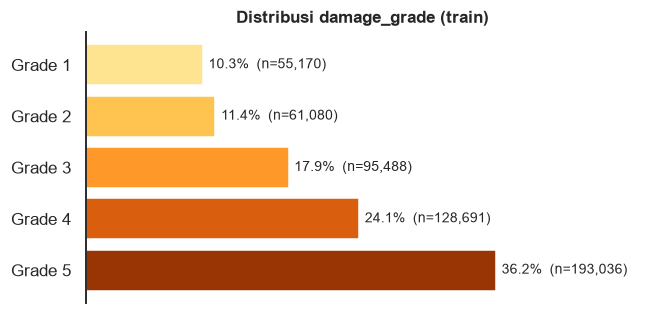

Rasio kelas terbesar : terkecil = 3.5 : 1
Akurasi baseline mayoritas = 0.362
Macro F1 baseline mayoritas = 0.106


In [5]:
vc = train[TARGET].value_counts().reindex(GRADE_ORDER)
pct = vc / vc.sum()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(GRADE_ORDER[::-1], pct[::-1], color=GRADE_COLORS[::-1])
for i, (g, p) in enumerate(zip(GRADE_ORDER[::-1], pct[::-1])):
    ax.text(p + 0.005, i, f"{p:.1%}  (n={vc[g]:,})", va="center", fontsize=9)
ax.set_xlim(0, pct.max() * 1.35)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("Distribusi damage_grade (train)")
save_fig("01_target_distribution")
plt.show()

# Baseline 'bodoh': tebak kelas mayoritas untuk semua baris
y_major = np.full(len(train), pct.idxmax())
print(f"Rasio kelas terbesar : terkecil = {vc.max() / vc.min():.1f} : 1")
print(f"Akurasi baseline mayoritas = {(train[TARGET] == y_major).mean():.3f}")
print(f"Macro F1 baseline mayoritas = {f1_score(train[TARGET], y_major, average='macro', labels=GRADE_ORDER, zero_division=0):.3f}")

Prediksi kelas mayoritas ("Grade 5") untuk seluruh observasi menghasilkan tingkat akurasi yang tampak memadai, namun nilai Macro F1 tertahan pada ~0,1 akibat kegagalan deteksi pada empat kelas minoritas (F1 = 0).

Kondisi ini mendasari pengabaian metrik akurasi, penerapan parameter class_weight="balanced", serta penggunaan StratifiedKFold pada tahap pemodelan. Nilai ~0,1 berfungsi sebagai batas bawah (baseline) minimal yang harus dilampaui oleh performa model.

# 4. Fitur numerik
Pertama lihat ringkasan kuantil — persentil 1% dan 99% membantu menemukan nilai ekstrem yang tersembunyi di balik rata-rata.

In [6]:
display(train[NUM_COLS].describe(percentiles=[.01, .25, .5, .75, .99]).T)

print("--- Nilai mencurigakan ---")
print(f"age_building == 999       : {(train['age_building'] == 999).sum():>4} baris  (kode 'tidak diketahui', bukan umur asli)")
print(f"age_building == 0         : {(train['age_building'] == 0).sum():>4} baris  (bangunan baru / dibulatkan)")
print(f"height_ft_pre_eq >= 50    : {(train['height_ft_pre_eq'] >= 50).sum():>4} baris  (tinggi 50-99 ft untuk rumah warga tidak masuk akal)")
print(f"plinth_area_sq_ft > 99%   : {(train['plinth_area_sq_ft'] > train['plinth_area_sq_ft'].quantile(.99)).sum():>4} baris  (right-tail panjang)")

,count,mean,std,min,1%,25%,50%,75%,99%,max
count_floors_pre_eq,"533,465.000",2.088,0.655,1.000,1.000,2.000,2.000,2.000,4.000,9.000
age_building,"533,465.000",24.337,64.999,0.000,1.000,9.000,16.000,27.000,90.000,999.000
plinth_area_sq_ft,"533,465.000",406.523,226.610,70.000,120.000,280.000,358.000,470.000,"1,222.000","5,000.000"
height_ft_pre_eq,"533,465.000",16.048,5.491,6.000,6.000,12.000,16.000,18.000,32.000,99.000


--- Nilai mencurigakan ---
age_building == 999       : 2198 baris  (kode 'tidak diketahui', bukan umur asli)
age_building == 0         : 3349 baris  (bangunan baru / dibulatkan)
height_ft_pre_eq >= 50    :  793 baris  (tinggi 50-99 ft untuk rumah warga tidak masuk akal)
plinth_area_sq_ft > 99%   : 5316 baris  (right-tail panjang)


**Temuan**: age_building = 999 adalah bukan umur sebenarnya, yang dapat mendistorsi statistik (rata-rata/standar deviasi) serta bias model linear.

**Solusi**: Nilai 999 dikonversi menjadi NaN melalui pipeline, diimputasi menggunakan median, dan ditambahkan fitur biner age_is_unknown sebagai indikator. Untuk visualisasi di bawah, nilai 999 sementara diubah menjadi NaN.

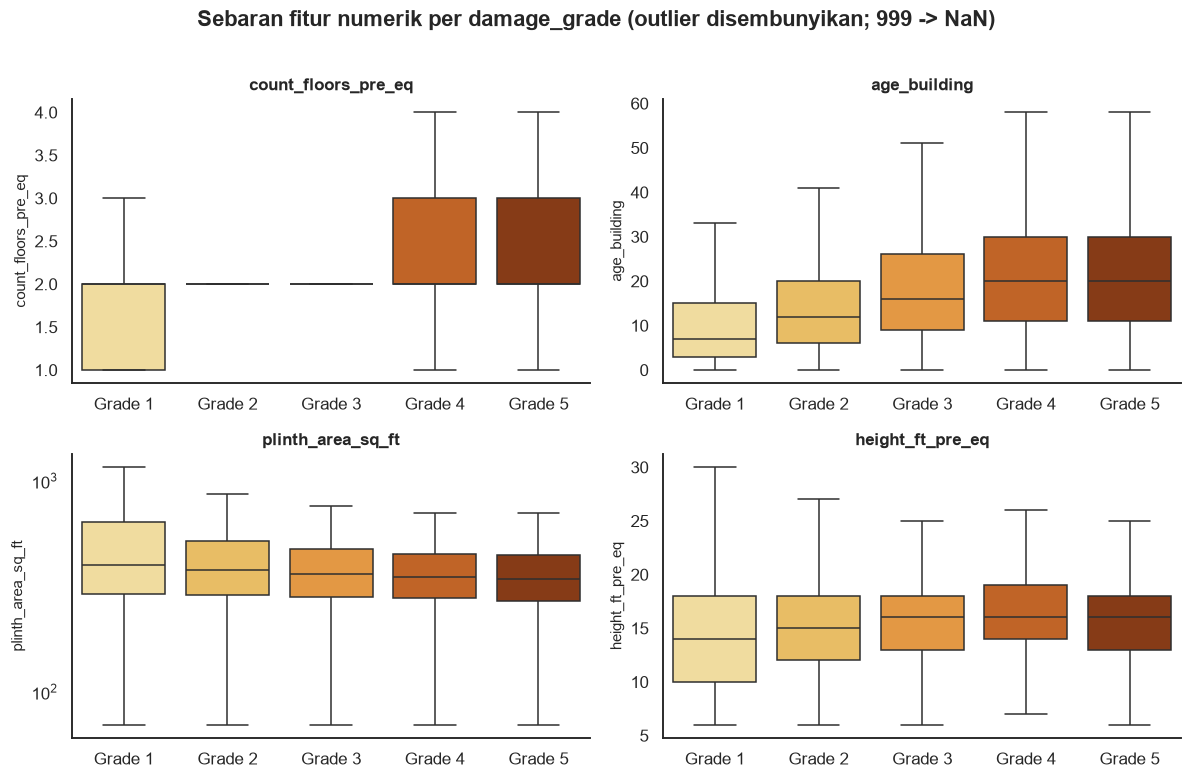

,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq
damage_grade,,,,
Grade 1,2.000,7.000,400.000,14.000
Grade 2,2.000,12.000,380.000,15.000
Grade 3,2.000,16.000,364.000,16.000
Grade 4,2.000,20.000,350.000,16.000
Grade 5,2.000,20.000,342.000,16.000


In [7]:
plot_df = train.copy()
plot_df["age_building"] = plot_df["age_building"].replace(999, np.nan)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.boxplot(data=plot_df, x=TARGET, y=col, order=GRADE_ORDER, hue=TARGET,
                hue_order=GRADE_ORDER, palette=GRADE_PALETTE, legend=False,
                showfliers=False, linewidth=1, ax=ax)
    if col == "plinth_area_sq_ft":
        ax.set_yscale("log")
    ax.set_xlabel("")
    ax.set_title(col)
fig.suptitle("Sebaran fitur numerik per damage_grade (outlier disembunyikan; 999 -> NaN)", y=1.01, fontweight="bold")
fig.tight_layout()
save_fig("02_numeric_by_grade")
plt.show()

display(plot_df.groupby(TARGET)[NUM_COLS].median().loc[GRADE_ORDER])

In [8]:
# Kekuatan hubungan monoton fitur numerik dengan target ordinal (Spearman)
grade_code = train[TARGET].map({g: i for i, g in enumerate(GRADE_ORDER, 1)})
spearman = pd.Series(
    {c: stats.spearmanr(plot_df[c], grade_code, nan_policy="omit")[0] for c in NUM_COLS}
).sort_values(key=np.abs, ascending=False)
print("Korelasi Spearman dengan damage_grade (1-5):")
display(spearman.to_frame("rho"))

Korelasi Spearman dengan damage_grade (1-5):


,rho
age_building,0.243
count_floors_pre_eq,0.198
plinth_area_sq_ft,-0.115
height_ft_pre_eq,0.095


* Bangunan yang rusak parah cenderung lebih tua (median ≈ 7 th di Grade 1 vs ≈ 20 th di Grade 4–5; Spearman ρ ≈ 0,24) dan bertingkat lebih banyak (ρ ≈ 0,20): Grade 1 umumnya 1–2 lantai, Grade 4–5 umumnya 2–3 lantai, sedangkan Grade 2–3 hampir seluruhnya 2 lantai.
* Luas dasar berkorelasi negatif lemah (ρ ≈ −0,11) dan tinggi positif lemah (ρ ≈ 0,09), bangunan kecil justru lebih rentan, kemungkinan karena konstruksinya lebih sederhana (lumpur/batu).
* Spearman hanya menangkap hubungan monoton dan tidak melihat interaksi (mis. umur × material); model tree-based dapat menangkapnya, sedangkan model linear perlu fitur turunan.

# 5. Fitur kategorik
Untuk setiap kategori, kita lihat komposisi damage_grade-nya (100% stacked bar). Baris diurutkan dari yang paling aman ke paling rawan (porsi Grade 4+5), dan n ditulis di label agar kategori langka yang estimasinya berisik mudah dikenali.

In [9]:
display(pd.DataFrame({
    "n_unique": train[CAT_COLS].nunique(),
    "top_category": [train[c].value_counts().index[0] for c in CAT_COLS],
    "top_share": [train[c].value_counts(normalize=True).iloc[0] for c in CAT_COLS],
    "n_cat_<1%": [(train[c].value_counts(normalize=True) < 0.01).sum() for c in CAT_COLS],
}, index=CAT_COLS))

,n_unique,top_category,top_share,n_cat_<1%
land_surface_condition,3,Flat,0.829,0
foundation_type,5,Mud mortar-Stone/Brick,0.825,1
roof_type,3,Bamboo/Timber-Light roof,0.661,0
ground_floor_type,5,Mud,0.811,2
other_floor_type,4,TImber/Bamboo-Mud,0.639,0
position,4,Not attached,0.793,1
plan_configuration,10,Rectangular,0.960,7
superstructure,11,has_superstructure_mud_mortar_stone,0.779,3


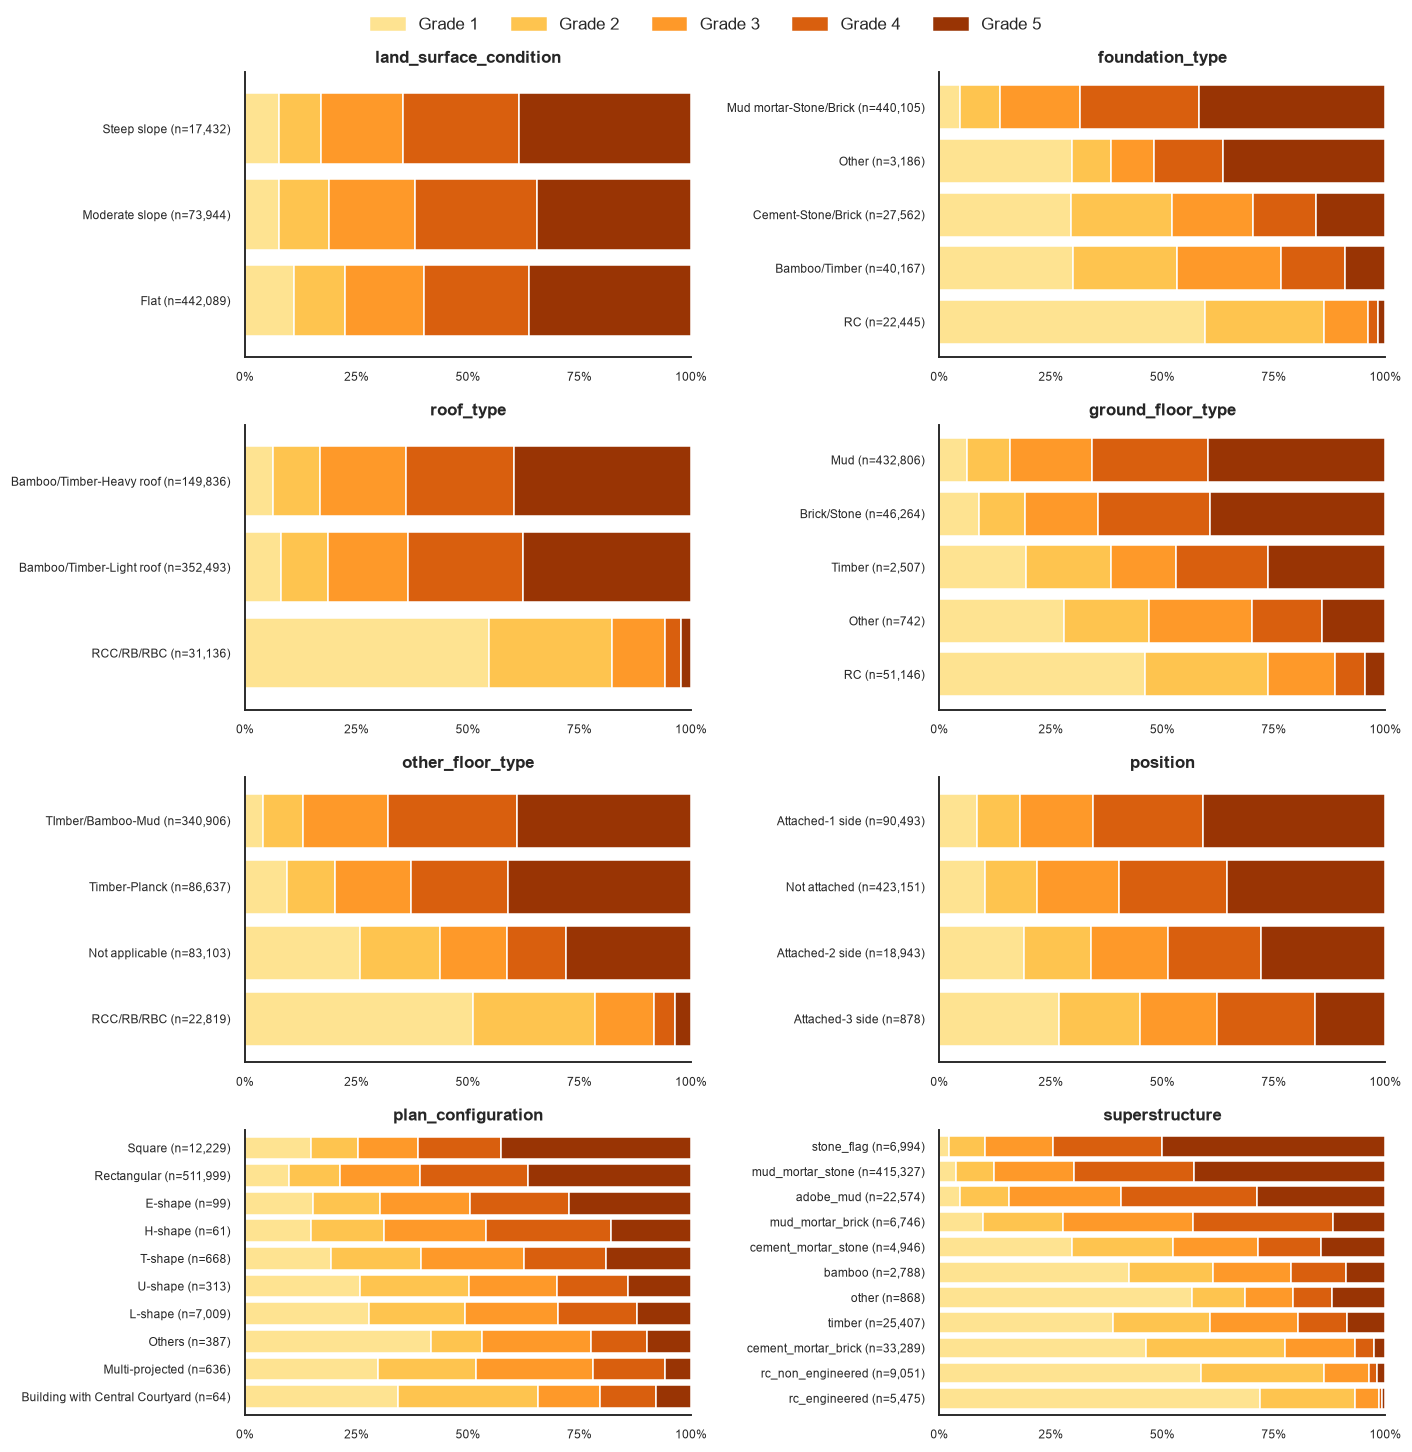

In [10]:
def plot_grade_mix(df: pd.DataFrame, col: str, ax: plt.Axes) -> None:
    """Gambar 100% stacked horizontal bar komposisi damage_grade per kategori.
    Kategori diurutkan menurut porsi Grade 4+5 (paling aman di bawah).
    Args:
        df: DataFrame berisi ``col`` dan kolom target.
        col: Nama kolom kategorik yang dianalisis.
        ax: Axes tujuan.
    """
    mix = pd.crosstab(df[col], df[TARGET], normalize="index").reindex(columns=GRADE_ORDER, fill_value=0)
    n = df[col].value_counts()
    mix = mix.loc[mix[["Grade 4", "Grade 5"]].sum(axis=1).sort_values().index]
    mix.plot.barh(stacked=True, ax=ax, color=GRADE_COLORS, width=0.82, legend=False, edgecolor="white")
    ax.set_yticklabels([f"{str(i).replace('has_superstructure_', '')} (n={n[i]:,})" for i in mix.index], fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_xticks([0, .25, .5, .75, 1])
    ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"], fontsize=8)
    ax.set_ylabel("")
    ax.set_title(col)


fig, axes = plt.subplots(4, 2, figsize=(13, 13))
for ax, col in zip(axes.ravel(), CAT_COLS):
    plot_grade_mix(train, col, ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GRADE_COLORS]
fig.legend(handles, GRADE_ORDER, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.02), frameon=False)
fig.tight_layout()
save_fig("03_categorical_grade_mix")
plt.show()

Semakin pekat warna cokelat tua ke arah kanan, semakin besar porsi bangunan dengan kerusakan berat. Kategori diurutkan dari yang paling aman (bawah) hingga yang paling rawan (atas). Perbedaan komposisi yang besar antarkategori (misalnya pada foundation_type dan roof_type) menunjukkan bahwa fitur tersebut bersifat diskriminatif.

Karena analisis menggunakan data full, proporsi pada kategori berukuran besar (misalnya Mud mortar-Stone/Brick, n = 440.105) sangat stabil. Kategori dengan n kecil (puluhan hingga ratusan baris, misalnya plan_configuration H-shape n = 61 dan Building with Central Courtyard n = 64) tetap memiliki estimasi yang tidak stabil akibat jumlah pengamatan yang sedikit. Kesimpulan sebaiknya tidak ditarik dari kategori semacam ini, dan pada tahap encoding kategori tersebut dapat digabungkan ke dalam kategori "jarang" (min_frequency).

# 6. Kolom wilayah: district_id, vdcmun_id, ward_id
Kolom ini bertipe integer, namun nominal & hierarkis (distrik ⊃ kota/desa ⊃ ward). Kita verifikasi hierarkinya, lalu lihat apakah wilayah memengaruhi kerusakan — secara fisik wilayah adalah proxy jarak ke episentrum dan jenis tanah.

In [11]:
print("Verifikasi hierarki kode:")
print(f"  ward_id   // 100 == vdcmun_id   : {(train['ward_id'] // 100 == train['vdcmun_id']).mean():.1%}")
print(f"  vdcmun_id // 100 == district_id : {(train['vdcmun_id'] // 100 == train['district_id']).mean():.1%}")
print(f"  building_id // 10^10 == district_id : {(train[ID_COL] // 10**10 == train['district_id']).mean():.1%}  (building_id memuat kode distrik)")

card = pd.DataFrame({
    "n_unik_train": train[GEO_COLS].nunique(),
    "n_unik_test": test[GEO_COLS].nunique(),
    "test_tak_terlihat_di_train": [(~test[c].isin(train[c])).mean() for c in GEO_COLS],
})
display(card)
ward_n = train["ward_id"].value_counts()
print(f"Median baris per ward: {ward_n.median():.0f} | ward dengan < 5 baris: {(ward_n < 5).mean():.1%}")

Verifikasi hierarki kode:
  ward_id   // 100 == vdcmun_id   : 100.0%
  vdcmun_id // 100 == district_id : 100.0%
  building_id // 10^10 == district_id : 100.0%  (building_id memuat kode distrik)


,n_unik_train,n_unik_test,test_tak_terlihat_di_train
district_id,11,11,0.000
vdcmun_id,110,110,0.000
ward_id,945,945,0.000


Median baris per ward: 541 | ward dengan < 5 baris: 0.0%


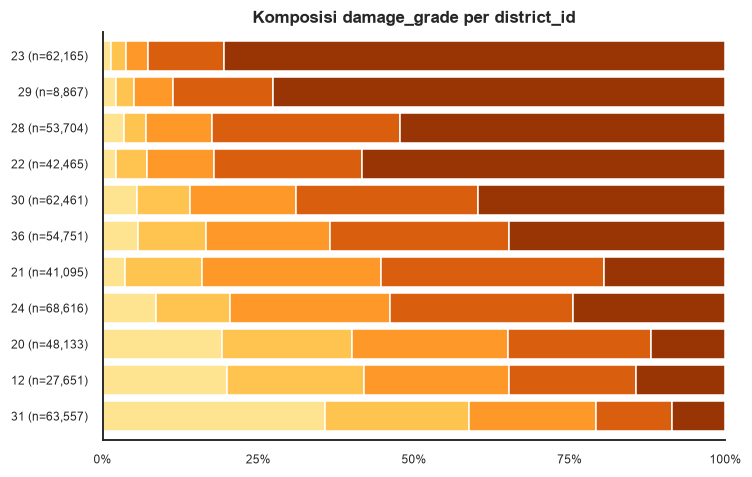

Porsi Grade 4-5 antar-distrik berkisar 21% - 93%


In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_grade_mix(train, "district_id", ax)
ax.set_title("Komposisi damage_grade per district_id")
fig.tight_layout()
save_fig("04_district_grade_mix")
plt.show()

g45 = (train.assign(g45=train[TARGET].isin(["Grade 4", "Grade 5"]))
            .groupby("district_id")["g45"].agg(["mean", "size"]).sort_values("mean"))
print(f"Porsi Grade 4-5 antar-distrik berkisar {g45['mean'].min():.0%} - {g45['mean'].max():.0%}")

Wilayah merupakan salah satu pembeda terkuat, tingkat kerusakan antardistrik berbeda sangat jauh meskipun tipe bangunannya mirip. Konsekuensinya terhadap preprocessing:
* district_id (11 level) dan vdcmun_id (110 level) dapat di-encode dengan One-Hot Encoding.
* ward_id (945 level) menghasilkan 945 kolom yang jarang apabila di-encode dengan One-Hot. Masalah ini diatasi dengan menggabungkan ward berfrekuensi rendah (min_frequency) atau menggunakan OrdinalEncoder untuk model berbasis tree. Pada data penuh, seluruh ward pada test terdapat pada train (0,0% ward baru), tetapi handle_unknown tetap digunakan sebagai pengaman.
* building_id dikeluarkan dari fitur karena merupakan pengenal unik, dan informasinya sudah terwakili oleh kolom wilayah.

## 7. Asosiasi fitur kategorik dengan target: uji Chi-square independensi
Untuk setiap fitur kategorik dilakukan uji hipotesis berikut:
- **H0:** fitur dan `damage_grade` saling bebas (distribusi grade sama pada seluruh kategori fitur).
- **H1:** fitur dan `damage_grade` tidak saling bebas.

Statistik uji pada tabel kontingensi berukuran r × k adalah:

$$\chi^2 = \sum \frac{(O - E)^2}{E}, \qquad E = \frac{\text{total baris} \times \text{total kolom}}{n}, \qquad df = (r-1)(k-1)$$

**Cara memeringkat:** Nilai p tidak informatif untuk membandingkan fitur karena pada n yang besar hampir seluruhnya mendekati 0. Di sisi lain, apabila H0 benar, nilai harapan χ² sama dengan `df`. Dengan demikian, rasio **χ² / df** dapat dibaca secara langsung: nilai sekitar 1 menunjukkan tidak adanya asosiasi, dan semakin jauh di atas 1 menunjukkan asosiasi yang semakin kuat.

**Asumsi:** observasi saling bebas, serta frekuensi harapan E ≥ 5 pada minimal 80% sel. Kolom `pct_E<5` digunakan untuk memeriksa asumsi kedua; nilai yang tinggi menunjukkan bahwa hasil uji untuk fitur tersebut kurang dapat diandalkan.

In [ ]:
def chi_square_test(df: pd.DataFrame, col: str, target: str = TARGET) -> dict:
    """Uji Chi-square independensi antara satu fitur kategorik dan target.
    Args:
        df: DataFrame yang memuat ``col`` dan ``target``.
        col: Nama fitur kategorik.
        target: Nama kolom target.
    Returns:
        Dict berisi statistik chi2, derajat bebas, rasio chi2/df, p-value, dan
        proporsi sel dengan frekuensi harapan < 5 (pemeriksaan asumsi).
    """
    table = pd.crosstab(df[col], df[target])
    chi2, p_value, dof, expected = stats.chi2_contingency(table)
    return {"feature": col, "chi2": chi2, "df": dof, "chi2_per_df": chi2 / dof,
            "p_value": p_value, "pct_E<5": (expected < 5).mean()}


nominal_cols = GEO_COLS + CAT_COLS
chi_df = (pd.DataFrame([chi_square_test(train, c) for c in nominal_cols])
            .sort_values("chi2_per_df", ascending=False).set_index("feature"))
display(chi_df.style.format({"chi2": "{:,.1f}", "chi2_per_df": "{:,.2f}",
                             "p_value": "{:.1e}", "pct_E<5": "{:.0%}"}))

,chi2,df,chi2_per_df,p_value,pct_E<5
feature,,,,,
roof_type,"87,838.8",8,"10,979.85",0.0e+00,0%
foundation_type,"139,808.1",16,"8,738.01",0.0e+00,0%
other_floor_type,"100,290.2",12,"8,357.52",0.0e+00,0%
ground_floor_type,"107,748.5",16,"6,734.28",0.0e+00,0%
district_id,"193,100.3",40,"4,827.51",0.0e+00,0%
superstructure,"191,520.5",40,"4,788.01",0.0e+00,0%
vdcmun_id,"291,608.7",436,668.83,0.0e+00,0%
position,"3,763.4",12,313.62,0.0e+00,0%
land_surface_condition,"1,492.9",8,186.61,0.0e+00,0%


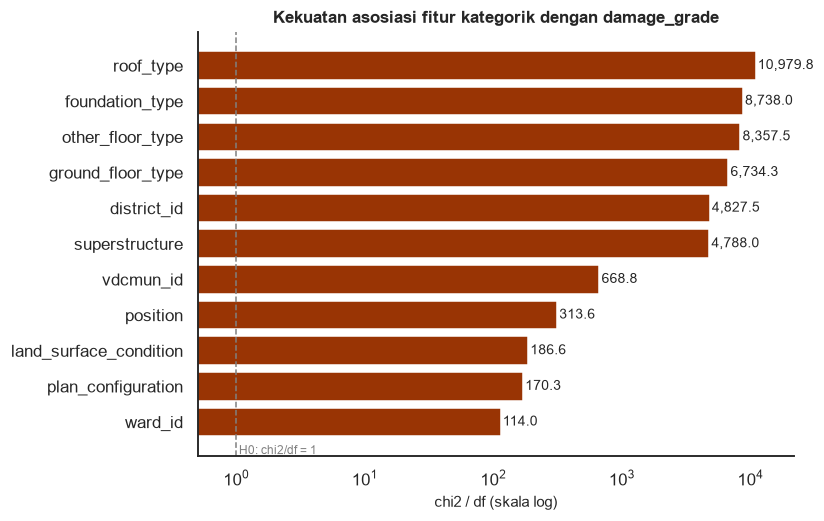

In [14]:
plot_chi = chi_df["chi2_per_df"].sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(plot_chi.index, plot_chi.values, color="#993404")
ax.axvline(1, color="gray", ls="--", lw=1)            # nilai harapan di bawah H0
ax.text(1.05, -0.9, "H0: chi2/df = 1", color="gray", fontsize=8)
for i, v in enumerate(plot_chi.values):
    ax.text(v * 1.04, i, f"{v:,.1f}", va="center", fontsize=9)
ax.set_xscale("log")
ax.set_xlim(0.5, plot_chi.max() * 2)
ax.set_xlabel("chi2 / df (skala log)")
ax.set_title("Kekuatan asosiasi fitur kategorik dengan damage_grade")
save_fig("05_chi_square_target")
plt.show()

Seluruh fitur memiliki χ²/df ≫ 1 dan nilai p ≈ 0. Dengan n = 533.465, hampir semua hubungan signifikan secara statistik, sehingga yang informatif adalah **peringkatnya**. Peringkat teratas ditempati oleh fitur jenis konstruksi (`roof_type` ≈ 10.980, `foundation_type` ≈ 8.738, `other_floor_type` ≈ 8.358, `ground_floor_type` ≈ 6.734), diikuti oleh `district_id` (≈ 4.828) dan `superstructure` (≈ 4.788). Fitur `position`, `land_surface_condition`, dan `plan_configuration` (≈ 170–314) memiliki asosiasi terendah, tetapi masih jauh di atas 1 sehingga **tidak boleh dikeluarkan hanya berdasarkan uji ini**. 

Catatan metodologis:
1. Uji ini hanya menilai hubungan **satu fitur terhadap target** dan tidak mengendalikan fitur lain. Oleh karena itu, kepentingan fitur akhir perlu dinilai dari model (misalnya *permutation importance*), bukan dari EDA.
2. χ²/df merupakan kekuatan asosiasi **per derajat bebas**, sehingga fitur dengan banyak level tampak lebih kecil: `vdcmun_id` (≈ 669) dan `ward_id` (≈ 114), padahal nilai χ² total keduanya justru yang terbesar (≈ 291.609 dan ≈ 430.353). Asumsi E ≥ 5 terpenuhi pada data penuh (0% sel dengan E < 5 pada seluruh fitur).
3. Nilai p sama dengan 0 untuk seluruh fitur sehingga tidak dapat membedakan satu fitur dari fitur lainnya.

# 8. Train vs Test
Model dilatih pada distribusi data latih. Apabila distribusi data uji berbeda, skor validasi silang yang baik dapat menyesatkan. Pemeriksaan dilakukan dengan (a) uji Kolmogorov–Smirnov dua sampel untuk fitur numerik, dan (b) pemeriksaan kategori yang muncul pada test tetapi tidak terdapat pada train untuk fitur kategorik.

Catatan statistik: pada n yang besar, uji KS akan signifikan bahkan untuk selisih yang sangat kecil. Oleh karena itu, perhatian difokuskan pada statistik D (ukuran efek), bukan pada nilai p.

In [15]:
ks = pd.DataFrame(
    {c: stats.ks_2samp(train[c].replace(999, np.nan).dropna(),
                       test[c].replace(999, np.nan).dropna())[:2] for c in NUM_COLS},
    index=["KS_D", "p_value"],
).T
display(ks)

unseen = {c: sorted(set(test[c].unique()) - set(train[c].unique())) for c in CAT_COLS + ["district_id", "vdcmun_id"]}
print("Kategori di test yang tidak ada di train:", {k: v for k, v in unseen.items() if v} or "tidak ada")
print(f"Baris test dengan ward_id baru: {(~test['ward_id'].isin(train['ward_id'])).mean():.1%}")
print(f"Test: proporsi age_building == 999 = {(test['age_building'] == 999).mean():.2%} | train = {(train['age_building'] == 999).mean():.2%}")

,KS_D,p_value
count_floors_pre_eq,0.000,1.000
age_building,0.003,0.207
plinth_area_sq_ft,0.002,0.689
height_ft_pre_eq,0.001,0.998


Kategori di test yang tidak ada di train: tidak ada
Baris test dengan ward_id baru: 0.0%
Test: proporsi age_building == 999 = 0.41% | train = 0.41%


Statistik KS D ≤ 0,003 untuk seluruh fitur numerik, tidak terdapat kategori baru pada test, 0% ward pada test yang tidak terdapat pada train, dan proporsi age_building == 999 identik (0,41% pada train maupun test). Dengan demikian, train dan test berasal dari populasi yang sama.

## 9. Kesimpulan EDA dan rencana preprocessing

## Temuan utama (data penuh: 533.465 baris train, 228.629 baris test)
| # | Temuan | Bukti | Konsekuensi |
|---|---|---|---|
| 1 | Distribusi target tidak seimbang (Grade 5 ≈ 36%, Grade 1 ≈ 10%) | Rasio 3,5 : 1; akurasi baseline mayoritas 0,362 sedangkan Macro F1 hanya 0,106 | Menggunakan `StratifiedKFold` dan `class_weight="balanced"`, serta melaporkan Macro F1 per kelas |
| 2 | Nilai tidak wajar pada fitur numerik | `age_building = 999` pada 2.198 baris (0,41%); `height_ft_pre_eq` ≥ 50 ft pada 793 baris; `plinth_area_sq_ft` berekor kanan panjang | `999` diubah menjadi `NaN`, imputasi median disertai indikator, *clipping* kuantil, dan transformasi log pada luas dasar |
| 3 | Jenis konstruksi sangat diskriminatif | χ²/df tertinggi: `roof_type` ≈ 10.980, `foundation_type` ≈ 8.738, `other_floor_type` ≈ 8.358, `ground_floor_type` ≈ 6.734 | Seluruh fitur struktur dipertahankan; ditambahkan fitur turunan jumlah elemen RC dan elemen lumpur |
| 4 | Wilayah merupakan pembeda yang kuat | χ²/df `district_id` ≈ 4.828 dan `vdcmun_id` ≈ 669; porsi Grade 4–5 antardistrik sekitar 20% hingga di atas 90% | Kolom kode wilayah diperlakukan sebagai **nominal**, bukan numerik |
| 5 | `ward_id` berkardinalitas tinggi | 945 level; 0% ward pada test yang tidak terdapat pada train | One-Hot dengan `min_frequency` atau Ordinal untuk model pohon; `handle_unknown` tetap digunakan |
| 6 | Fitur dengan asosiasi terendah | `position` ≈ 314, `land_surface_condition` ≈ 187, `plan_configuration` ≈ 170 (tetap ≫ 1) | Dipertahankan terlebih dahulu; kontribusinya dinilai dari model, bukan dari uji ini |
| 7 | Asumsi uji Chi-square terpenuhi | 0% sel dengan E < 5 pada semua fitur; nilai p = 0 untuk semua fitur | Menggunakan peringkat χ²/df, bukan nilai p |
| 8 | Tidak terdapat distribution shift | KS D ≤ 0,003; tidak ada kategori baru; porsi `age_building == 999` sama (0,41%) | Validasi silang acak berstrata representatif |
| 9 | Duplikat fitur | 34.062 baris (≈ 6,4%) memiliki fitur identik | Tidak dihapus; optimisme skor validasi silang perlu diperhatikan |

## Keputusan preprocessing (diimplementasikan pada `scripts/`)
- **Dikeluarkan:** `building_id` (pengenal unik).
- **Pembersihan (`DataCleaner`):** `age_building == 999` diubah menjadi `NaN`; kolom wilayah dijadikan string agar diperlakukan sebagai nominal.
- **Fitur turunan (`FeatureEngineer`):** `age_is_unknown`, `age_is_new`, `log_plinth_area`, `area_per_floor`, `height_per_floor`, `n_rc_elements`, dan `n_mud_elements`.
- **Fitur numerik:** `SimpleImputer(median)`, kemudian `QuantileClipper`, kemudian `StandardScaler` (standardisasi hanya untuk model linear).
- **Fitur kategorik (8 kolom bangunan, `district_id`, dan `vdcmun_id`):** `OneHotEncoder` (model linear) atau `OrdinalEncoder` (model pohon). **`ward_id`:** One-Hot dengan `min_frequency` atau Ordinal.
- **Kandidat model (tanpa Neural Network):** Logistic Regression (baseline; OvR dan multinomial), Random Forest, dan HistGradientBoosting; strategi OvR dan OvO dibandingkan sesuai materi tugas.
- **Evaluasi:** Macro F1 dengan `StratifiedKFold(5)`, disertai confusion matrix.

## Implikasi bagi manajemen
> Tipe konstruksi dan lokasi bangunan merupakan dua penentu utama tingkat kerusakan. Sekitar 7 dari 10 bangunan berfondasi *mud mortar* mengalami kerusakan berat, sedangkan bangunan beton bertulang (RC) hampir seluruhnya mengalami kerusakan ringan; tingkat kerusakan juga berbeda jauh antardistrik. Program rekonstruksi dan perkuatan (*retrofit*) sebaiknya memprioritaskan bangunan berfondasi *mud mortar* di distrik berisiko tinggi.

## Limitasi dan risiko
- **Asosiasi tidak identik dengan kausalitas.** Bangunan *mud mortar* juga cenderung lebih tua dan terkonsentrasi pada distrik tertentu (*confounding*). Uji Chi-square dan korelasi Spearman tidak mengendalikan variabel lain, sehingga kepentingan fitur akhir perlu dinilai dari model (misalnya *permutation importance*), bukan dari EDA.
- **Uji Chi-square** hanya mengukur asosiasi marginal satu fitur; interaksi (umur × material, distrik × material) tidak tertangkap, dan χ²/df memberikan nilai yang lebih kecil bagi fitur dengan banyak level.
- **Label ordinal diperlakukan secara nominal** karena metrik yang digunakan adalah Macro F1; informasi urutan Grade 1 < … < Grade 5 tidak dimanfaatkan. Pendekatan ordinal (misalnya regresi dengan *threshold tuning*) dapat dicoba sebagai eksperimen tambahan.
- **Penanganan sentinel `999`** mengasumsikan bahwa nilai tersebut berarti "tidak diketahui". `metadata.csv` tidak mengonfirmasi hal ini (hanya menyebutkan umur dalam tahun), sehingga penanganan tersebut merupakan asumsi berdasarkan pola data.
- **Kolom `superstructure`** merupakan versi ringkas dari 11 flag material pada metadata; bangunan bermaterial campuran hanya terwakili oleh satu label, sehingga fitur ini dapat kurang informatif dibandingkan data aslinya.